In [1]:
# CAREER NAVIGATOR
# ANN - EMPLOYABILITY SCORE PREDICTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import random
import warnings
import tensorflow as tf

from pathlib import Path

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "evaluation"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project Directory:", PROJECT_ROOT)
print("Processed Data:", PROCESSED_DIR)
print("Model Directory:", MODEL_DIR)
print("Report Directory:", REPORT_DIR)

Project Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator
Processed Data: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\dataset\processed
Model Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models
Report Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\reports\evaluation


In [3]:
X_train = np.load(PROCESSED_DIR / "X_train.npy").astype("float32")
X_val = np.load(PROCESSED_DIR / "X_val.npy").astype("float32")
X_test = np.load(PROCESSED_DIR / "X_test.npy").astype("float32")

y_train = np.load(
    PROCESSED_DIR / "y_train_employability.npy"
).astype("float32")

y_val = np.load(
    PROCESSED_DIR / "y_val_employability.npy"
).astype("float32")

y_test = np.load(
    PROCESSED_DIR / "y_test_employability.npy"
).astype("float32")

print("Employability dataset loaded successfully!")

print("\nInput dimensions:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTarget dimensions:")
print("Training:", y_train.shape)
print("Validation:", y_val.shape)
print("Testing:", y_test.shape)

print("\nTarget score range:")
print("Minimum:", y_train.min())
print("Maximum:", y_train.max())

Employability dataset loaded successfully!

Input dimensions:
Training: (10500, 65)
Validation: (2250, 65)
Testing: (2250, 65)

Target dimensions:
Training: (10500,)
Validation: (2250,)
Testing: (2250,)

Target score range:
Minimum: 29.44
Maximum: 82.77


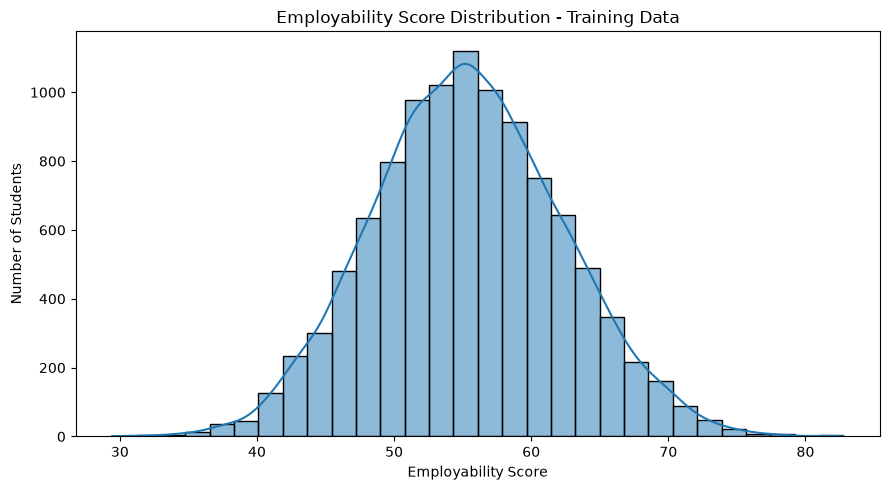


Employability Score Statistics:
count    10500.00
mean        55.37
std          6.91
min         29.44
25%         50.68
50%         55.25
75%         60.01
max         82.77
dtype: float64


In [4]:
plt.figure(figsize=(9, 5))

sns.histplot(
    y_train,
    bins=30,
    kde=True
)

plt.title("Employability Score Distribution - Training Data")
plt.xlabel("Employability Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

print("\nEmployability Score Statistics:")
print(pd.Series(y_train).describe().round(2))

In [5]:
employability_ann = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dropout(0.30),

    Dense(1, activation="linear")
])

employability_ann.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

employability_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,817 (73.50 KB)

 Trainable params: 18,817 (73.50 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
employability_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "ann_employability_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=0.00001,
        verbose=1
    )
]

print("Employability ANN callbacks configured!")

Employability ANN callbacks configured!


In [7]:
employability_history = employability_ann.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=employability_callbacks,
    verbose=1
)

print("\nEmployability ANN training completed!")

print(
    "Epochs trained:",
    len(employability_history.history["loss"])
)

print(
    "Best validation loss:",
    min(employability_history.history["val_loss"])
)

Epoch 1/100
327/329 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 499.8708 - mean_absolute_error: 16.0448
Epoch 1: val_loss improved from None to 34.68661, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_employability_best.keras

Epoch 1: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_employability_best.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 498.5380 - mean_absolute_error: 16.0175 - val_loss: 34.6866 - val_mean_absolute_error: 4.7025 - learning_rate: 0.0010
Epoch 2/100
321/329 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 124.2355 - mean_absolute_error: 8.8998
Epoch 2: val_loss improved from 34.68661 to 32.48826, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_employability_best.keras

Epoch 2: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_employability_best.keras
329/329 ━━

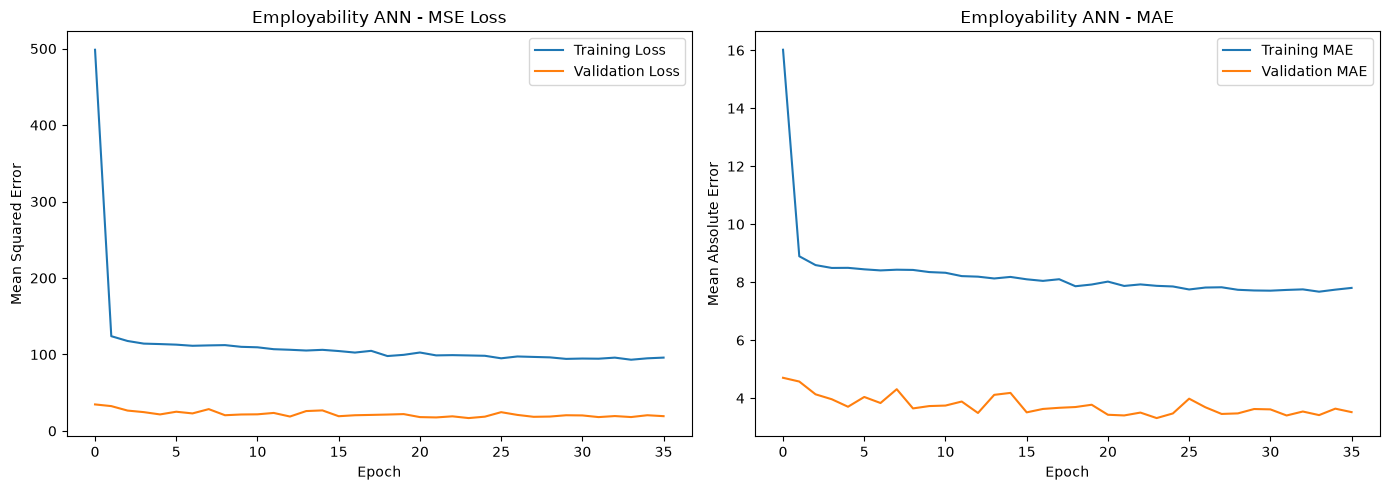

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    employability_history.history["loss"],
    label="Training Loss"
)

axes[0].plot(
    employability_history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Employability ANN - MSE Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error")
axes[0].legend()

axes[1].plot(
    employability_history.history["mean_absolute_error"],
    label="Training MAE"
)

axes[1].plot(
    employability_history.history["val_mean_absolute_error"],
    label="Validation MAE"
)

axes[1].set_title("Employability ANN - MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean Absolute Error")
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
employability_predictions = employability_ann.predict(
    X_val,
    verbose=0
).flatten()

# Keep predictions within the valid score range
employability_predictions = np.clip(
    employability_predictions,
    0,
    100
)

prediction_comparison = pd.DataFrame({
    "Actual Score": y_val[:15],
    "Predicted Score": employability_predictions[:15]
})

prediction_comparison["Error"] = (
    prediction_comparison["Actual Score"] -
    prediction_comparison["Predicted Score"]
)

display(prediction_comparison.round(2))

,Actual Score,Predicted Score,Error
0,43.450001,50.119999,-6.67
1,54.290001,53.950001,0.34
2,47.389999,50.189999,-2.80
3,55.730000,57.619999,-1.89
4,62.650002,57.110001,5.54
5,40.880001,44.110001,-3.23
6,60.660000,61.430000,-0.77
7,53.560001,51.509998,2.05
8,52.480000,48.810001,3.67
9,65.919998,62.410000,3.51


In [10]:
employability_ann_results = {
    "Model": "ANN",

    "MAE": mean_absolute_error(
        y_val,
        employability_predictions
    ),

    "MSE": mean_squared_error(
        y_val,
        employability_predictions
    ),

    "RMSE": np.sqrt(
        mean_squared_error(
            y_val,
            employability_predictions
        )
    ),

    "R2": r2_score(
        y_val,
        employability_predictions
    )
}

employability_ann_results_df = pd.DataFrame([
    employability_ann_results
])

print("EMPLOYABILITY ANN VALIDATION RESULTS")
print("=" * 55)

display(employability_ann_results_df.round(4))

EMPLOYABILITY ANN VALIDATION RESULTS


,Model,MAE,MSE,RMSE,R2
0,ANN,3.3127,16.8285,4.1023,0.6484


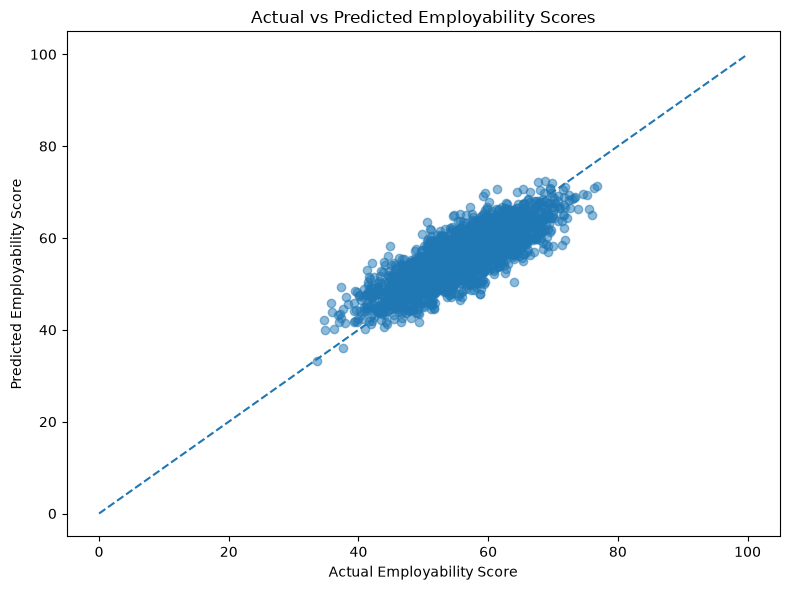

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    employability_predictions,
    alpha=0.5
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--"
)

plt.title("Actual vs Predicted Employability Scores")
plt.xlabel("Actual Employability Score")
plt.ylabel("Predicted Employability Score")

plt.tight_layout()
plt.show()

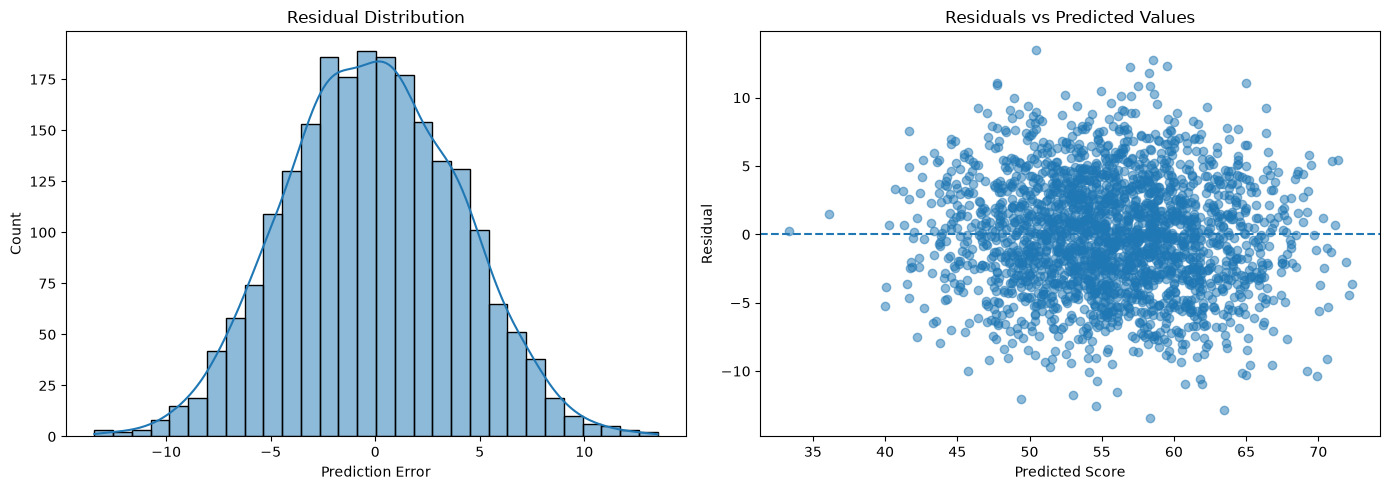

In [12]:
residuals = y_val - employability_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    residuals,
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Residual Distribution")
axes[0].set_xlabel("Prediction Error")

axes[1].scatter(
    employability_predictions,
    residuals,
    alpha=0.5
)

axes[1].axhline(
    y=0,
    linestyle="--"
)

axes[1].set_title("Residuals vs Predicted Values")
axes[1].set_xlabel("Predicted Score")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

In [13]:
baseline_candidates = [
    REPORT_DIR / "baseline_regression_results.csv",
    REPORT_DIR / "baseline_model_results.csv",
    REPORT_DIR / "baseline_employability_results.csv"
]

baseline_path = next(
    (path for path in baseline_candidates if path.exists()),
    None
)

if baseline_path is None:
    raise FileNotFoundError(
        "Baseline regression results CSV not found. "
        "Check reports/evaluation for your baseline regression file."
    )

baseline_df = pd.read_csv(baseline_path)

employability_baseline = baseline_df[
    baseline_df["Task"] == "Employability Score"
].copy()

if employability_baseline.empty:
    raise ValueError(
        "Employability Score results not found in baseline CSV."
    )

print("Baseline regression results loaded successfully!")

display(employability_baseline)

Baseline regression results loaded successfully!


,Task,Model,MAE,MSE,RMSE,R2
0,Employability Score,Linear Regression,3.126124,15.221093,3.901422,0.681947
1,Employability Score,Random Forest,3.430106,18.400842,4.289620,0.615504
2,Employability Score,Decision Tree,5.001720,39.361550,6.273878,0.177519


In [14]:
baseline_comparison = employability_baseline[
    ["Model", "MAE", "MSE", "RMSE", "R2"]
].copy()

ann_comparison = pd.DataFrame([{
    "Model": "ANN",
    "MAE": employability_ann_results["MAE"],
    "MSE": employability_ann_results["MSE"],
    "RMSE": employability_ann_results["RMSE"],
    "R2": employability_ann_results["R2"]
}])

employability_comparison = pd.concat(
    [baseline_comparison, ann_comparison],
    ignore_index=True
)

employability_comparison = employability_comparison.sort_values(
    "MAE",
    ascending=True
).reset_index(drop=True)

print("EMPLOYABILITY - BASELINE VS ANN")
print("=" * 60)

display(employability_comparison.round(4))

EMPLOYABILITY - BASELINE VS ANN


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,3.1261,15.2211,3.9014,0.6819
1,ANN,3.3127,16.8285,4.1023,0.6484
2,Random Forest,3.4301,18.4008,4.2896,0.6155
3,Decision Tree,5.0017,39.3616,6.2739,0.1775


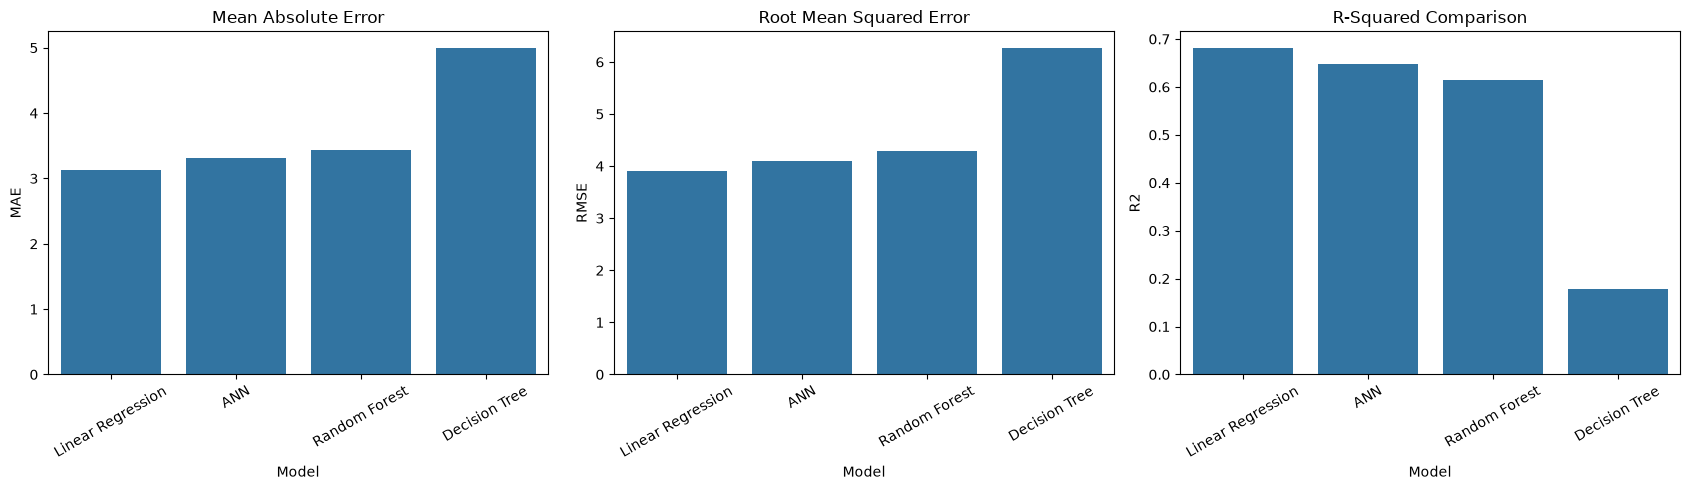

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    ("MAE", "Mean Absolute Error"),
    ("RMSE", "Root Mean Squared Error"),
    ("R2", "R-Squared Comparison")
]

for ax, (metric, title) in zip(axes, metrics):

    sns.barplot(
        data=employability_comparison,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [16]:
employability_ann.save(
    MODEL_DIR / "ann_employability_final.keras"
)

pd.DataFrame(
    employability_history.history
).to_csv(
    REPORT_DIR / "ann_employability_training_history.csv",
    index=False
)

employability_ann_results_df.to_csv(
    REPORT_DIR / "ann_employability_metrics.csv",
    index=False
)

employability_comparison.to_csv(
    REPORT_DIR / "employability_baseline_ann_comparison.csv",
    index=False
)

print("Employability ANN artifacts saved successfully!")

Employability ANN artifacts saved successfully!


In [17]:
employability_artifacts = [
    MODEL_DIR / "ann_employability_best.keras",
    MODEL_DIR / "ann_employability_final.keras",

    REPORT_DIR / "ann_employability_training_history.csv",
    REPORT_DIR / "ann_employability_metrics.csv",
    REPORT_DIR / "employability_baseline_ann_comparison.csv"
]

missing_artifacts = []

print("EMPLOYABILITY ANN - ARTIFACT VERIFICATION")
print("=" * 65)

for artifact in employability_artifacts:

    exists = artifact.exists()

    print(
        f"{artifact.name}:",
        "FOUND" if exists else "MISSING"
    )

    if not exists:
        missing_artifacts.append(artifact.name)

print("\nMissing artifacts:", missing_artifacts)

assert not missing_artifacts, "Some employability ANN artifacts are missing!"

print("\nALL EMPLOYABILITY ANN ARTIFACTS VERIFIED!")

EMPLOYABILITY ANN - ARTIFACT VERIFICATION
ann_employability_best.keras: FOUND
ann_employability_final.keras: FOUND
ann_employability_training_history.csv: FOUND
ann_employability_metrics.csv: FOUND
employability_baseline_ann_comparison.csv: FOUND

Missing artifacts: []

ALL EMPLOYABILITY ANN ARTIFACTS VERIFIED!
